# Sales Data Analysis using Python

**Tools:** Python, pandas, NumPy, Matplotlib

In this project I analysed the sales data of a general store (Bihar) using pandas.
Steps I followed:
1. Load the data and check it
2. Clean the data (missing values, duplicates, wrong city names)
3. Analyse sales (top products, monthly trend, city wise, payment mode)
4. Make charts and write my findings

**Note:** This is a sample dataset (10,000 orders, 2024-2025) which I created with `generate_data.py` for practice.

## 1. Import libraries and load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("data/sales_data.csv")
df.head()

,order_id,order_date,city,category,product,quantity,unit_price,payment_mode
0,ORD08977,2024-10-03,Muzaffarpur,Personal Care,Soap,5,37.0,Cash
1,ORD00459,2024-02-12,Muzaffarpur,Snacks,Namkeen,2,29.0,Cash
2,ORD03141,2024-10-24,Bhagalpur,Grocery,Tea 500g,6,232.0,UPI
3,ORD03904,2024-07-31,Gaya,Grocery,Atta 5kg,5,220.0,UPI
4,ORD05520,2025-04-21,Gaya,Grocery,Atta 5kg,4,239.0,Cash


## 2. Understanding the data

In [2]:
print("Rows and columns:", df.shape)
print()
df.info()

Rows and columns: (10250, 8)

<class 'pandas.DataFrame'>
RangeIndex: 10250 entries, 0 to 10249
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   order_id      10250 non-null  str    
 1   order_date    10250 non-null  str    
 2   city          10148 non-null  str    
 3   category      10250 non-null  str    
 4   product       10250 non-null  str    
 5   quantity      10250 non-null  int64  
 6   unit_price    10250 non-null  float64
 7   payment_mode  10046 non-null  str    
dtypes: float64(1), int64(1), str(6)
memory usage: 640.8 KB


In [ ]:
# how many missing values in each column
print(df.isnull().sum())
print()
# how many duplicate rows
print("Duplicate rows:", df.duplicated().sum())

order_id          0
order_date        0
city            102
category          0
product           0
quantity          0
unit_price        0
payment_mode    204
dtype: int64

Duplicate rows: 250


In [4]:
# city names - some are in lower case or have extra spaces
df["city"].value_counts()

city
Muzaffarpur      2911
Patna            2350
Darbhanga        1417
Gaya             1215
Bhagalpur         971
Hajipur           783
muzaffarpur       109
patna              77
 Muzaffarpur       62
 Patna             43
darbhanga          37
 Darbhanga         37
gaya               33
hajipur            24
 Gaya              23
bhagalpur          22
 Bhagalpur         14
 Hajipur           11
 muzaffarpur        4
 darbhanga          3
 patna              2
Name: count, dtype: int64

## 3. Data cleaning

Problems I found:
- 250 duplicate rows
- missing values in `city` and `payment_mode`
- city names written in different ways ("patna", " Patna ")
- `order_date` is stored as text

In [5]:
# 1. remove duplicate rows
df = df.drop_duplicates()
print("Rows after removing duplicates:", df.shape[0])

# 2. fix city names (remove spaces, make first letter capital)
df["city"] = df["city"].str.strip().str.title()

# 3. fill missing values
df["city"] = df["city"].fillna("Unknown")
df["payment_mode"] = df["payment_mode"].fillna("Unknown")

# 4. change order_date to date type
df["order_date"] = pd.to_datetime(df["order_date"])

# check again
print()
print(df.isnull().sum())

Rows after removing duplicates: 10000

order_id        0
order_date      0
city            0
category        0
product         0
quantity        0
unit_price      0
payment_mode    0
dtype: int64


In [6]:
# new columns for analysis
df["total_sales"] = df["quantity"] * df["unit_price"]
df["month"] = df["order_date"].dt.to_period("M")
df["year"] = df["order_date"].dt.year

df.head()

,order_id,order_date,city,category,product,quantity,unit_price,payment_mode,total_sales,month,year
0,ORD08977,2024-10-03,Muzaffarpur,Personal Care,Soap,5,37.0,Cash,185.0,2024-10,2024
1,ORD00459,2024-02-12,Muzaffarpur,Snacks,Namkeen,2,29.0,Cash,58.0,2024-02,2024
2,ORD03141,2024-10-24,Bhagalpur,Grocery,Tea 500g,6,232.0,UPI,1392.0,2024-10,2024
3,ORD03904,2024-07-31,Gaya,Grocery,Atta 5kg,5,220.0,UPI,1100.0,2024-07,2024
4,ORD05520,2025-04-21,Gaya,Grocery,Atta 5kg,4,239.0,Cash,956.0,2025-04,2025


## 4. Analysis

In [7]:
total_sales = df["total_sales"].sum()
total_orders = df["order_id"].nunique()
avg_order = df["total_sales"].mean()

print("Total sales      : Rs.", int(total_sales))
print("Total orders     :", total_orders)
print("Average order    : Rs.", round(avg_order, 2))
print()
print(df.groupby("year")["total_sales"].sum())

Total sales      : Rs. 4703090
Total orders     : 10000
Average order    : Rs. 470.31

year
2024    2346782.0
2025    2356308.0
Name: total_sales, dtype: float64


### 4.1 Top 5 products by sales

product
Rice 5kg          1131659.0
Atta 5kg           806652.0
Tea 500g           771045.0
Mustard Oil 1L     541052.0
Shampoo            367772.0
Name: total_sales, dtype: float64


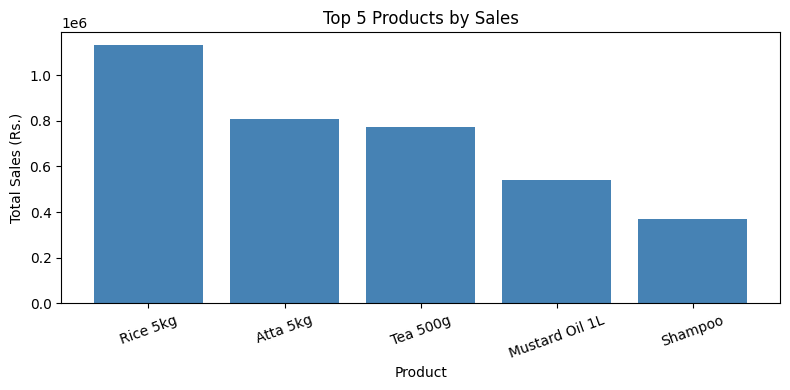

In [ ]:
top_products = df.groupby("product")["total_sales"].sum().sort_values(ascending=False).head(5)
print(top_products)

plt.figure(figsize=(8, 4))
plt.bar(top_products.index, top_products.values, color="steelblue")
plt.title("Top 5 Products by Sales")
plt.xlabel("Product")
plt.ylabel("Total Sales (Rs.)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("charts/top_products.png")
plt.show()

### 4.2 Category wise sales

category
Grocery          3401187.0
Personal Care     794026.0
Stationery        338577.0
Snacks            169300.0
Name: total_sales, dtype: float64

category
Grocery          72.3
Personal Care    16.9
Stationery        7.2
Snacks            3.6
Name: total_sales, dtype: float64


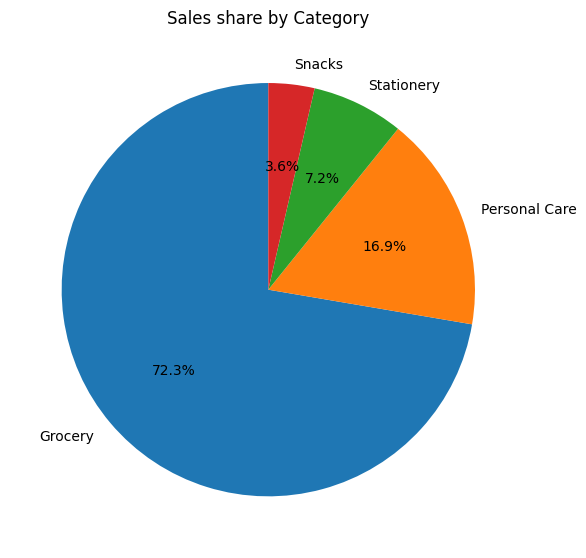

In [9]:
category_sales = df.groupby("category")["total_sales"].sum().sort_values(ascending=False)
print(category_sales)
print()
print((category_sales / total_sales * 100).round(1))

plt.figure(figsize=(6, 6))
plt.pie(category_sales.values, labels=category_sales.index, autopct="%1.1f%%", startangle=90)
plt.title("Sales share by Category")
plt.tight_layout()
plt.savefig("charts/category_share.png")
plt.show()

### 4.3 Monthly sales trend

month
2024-10    303731.0
2024-11    298941.0
2025-11    298673.0
2025-10    291865.0
Freq: M, Name: total_sales, dtype: float64

month
2025-07    122918.0
2024-06    132388.0
2025-08    135562.0
Freq: M, Name: total_sales, dtype: float64


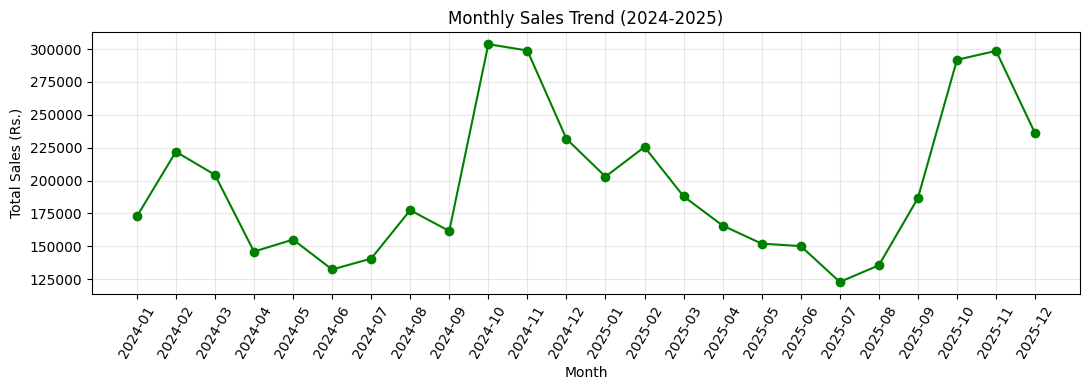

In [10]:
monthly_sales = df.groupby("month")["total_sales"].sum()
print(monthly_sales.sort_values(ascending=False).head(4))
print()
print(monthly_sales.sort_values().head(3))

plt.figure(figsize=(11, 4))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker="o", color="green")
plt.title("Monthly Sales Trend (2024-2025)")
plt.xlabel("Month")
plt.ylabel("Total Sales (Rs.)")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("charts/monthly_trend.png")
plt.show()

### 4.4 City wise sales

city
Muzaffarpur    1401742.0
Patna          1144224.0
Darbhanga       653166.0
Gaya            614294.0
Bhagalpur       471825.0
Hajipur         371623.0
Unknown          46216.0
Name: total_sales, dtype: float64


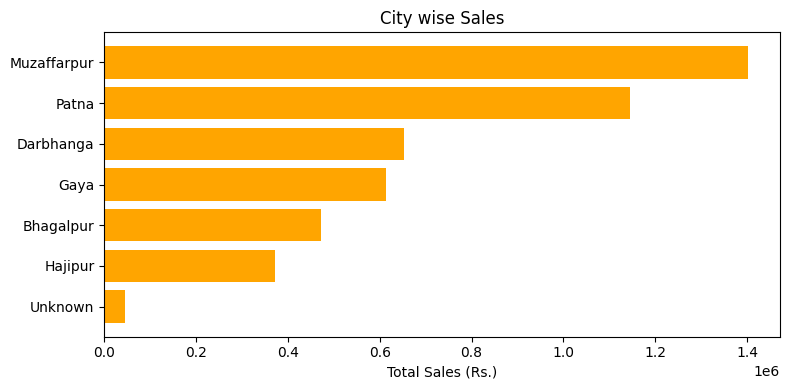

In [11]:
city_sales = df.groupby("city")["total_sales"].sum().sort_values(ascending=False)
print(city_sales)

plt.figure(figsize=(8, 4))
plt.barh(city_sales.index[::-1], city_sales.values[::-1], color="orange")
plt.title("City wise Sales")
plt.xlabel("Total Sales (Rs.)")
plt.tight_layout()
plt.savefig("charts/city_sales.png")
plt.show()

### 4.5 Payment mode

payment_mode
Cash       44.8
UPI        43.0
Card       10.3
Unknown     2.0
Name: count, dtype: float64


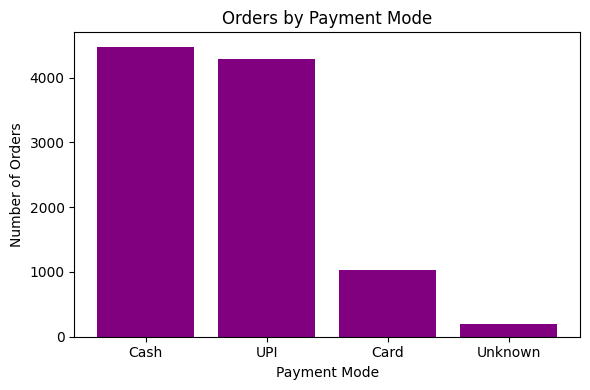

In [12]:
payment_count = df["payment_mode"].value_counts()
print((payment_count / len(df) * 100).round(1))

plt.figure(figsize=(6, 4))
plt.bar(payment_count.index, payment_count.values, color="purple")
plt.title("Orders by Payment Mode")
plt.xlabel("Payment Mode")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.savefig("charts/payment_mode.png")
plt.show()

## 5. Save cleaned data

In [13]:
df.to_csv("data/sales_data_cleaned.csv", index=False)
print("Cleaned file saved. Rows:", df.shape[0])

Cleaned file saved. Rows: 10000


## 6. My findings

- Total sales in 2 years were about **Rs. 47 lakh** from 10,000 orders. Average order value is around Rs. 470.
- **Grocery** gives most of the sales (about 72%). Personal Care is second (about 17%).
- **Rice 5kg** is the top product (about Rs. 11.3 lakh), then Atta 5kg and Tea 500g.
- Sales are highest in **October and November** (festival season, about Rs. 3 lakh per month) and lowest in **June-August** (about Rs. 1.2-1.4 lakh).
- **Muzaffarpur** (about 30%) and **Patna** (about 24%) are the two best cities.
- Cash (45%) and UPI (43%) are almost equal, card is only about 10%.

**What the shop can do:** keep more stock of rice, atta and tea before Oct-Nov, give offers in the low sales months, and promote UPI/card payment more.